# Figure 3a/b: chr7 prediction metrics across five cell lines

Apply the original window-quality filter, and plot the PCC and Spearman distributions. These figures summarize existing model-evaluation results.

Run the cells in order. The two boxplots are embedded below.


## Imports and data directory


In [1]:
from pathlib import Path
from io import BytesIO
import csv

import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, Markdown, display

cwd = Path.cwd().resolve()
RES = next((parent / "data" / "cell_metrics"
            for parent in [cwd, *cwd.parents]
            if (parent / "data" / "cell_metrics" / "HFFC6_chr7.csv").is_file()), None)
if RES is None:
    raise FileNotFoundError("Cannot find the repository's data/cell_metrics directory.")


## Parameters and inputs

In [3]:
CHROMOSOME = "chr7"
CELLS = [("HFFC6", "HFF"), ("H1HESC", "H1HESC"), ("K562", "K562"),
         ("MCF7", "MCF7"), ("IMR90v2", "IMR90")]
NONZERO_FRAC_MIN = 0.01


## Window quality table

In [7]:
chrom = CHROMOSOME
quality: dict[str, dict[str, float]] = {}
qp = RES / f"{chrom}_target_quality.csv"
if qp.is_file():
    with qp.open() as fh:
        for row in csv.DictReader(fh):
            quality.setdefault(row["cell"], {})[row["window"]] = float(row["nonzero_frac"])

## Read and filter window metrics


In [8]:
data = {}
for cell, label in CELLS:
    path = RES / f"{cell}_{chrom}.csv"
    with path.open() as handle:
        rows = list(csv.DictReader(handle))
    keep = [row for row in rows
            if quality.get(cell, {}).get(row["window"], 1.0) >= NONZERO_FRAC_MIN
            and row["pcc_sm"] not in ("", "nan", "NaN")]
    data[label] = {key: np.array([float(row[key]) for row in keep])
                   for key in ("pcc_sm", "spearman_sm")}


## Generate boxplots

**fig3a_pcc_chr7.png**

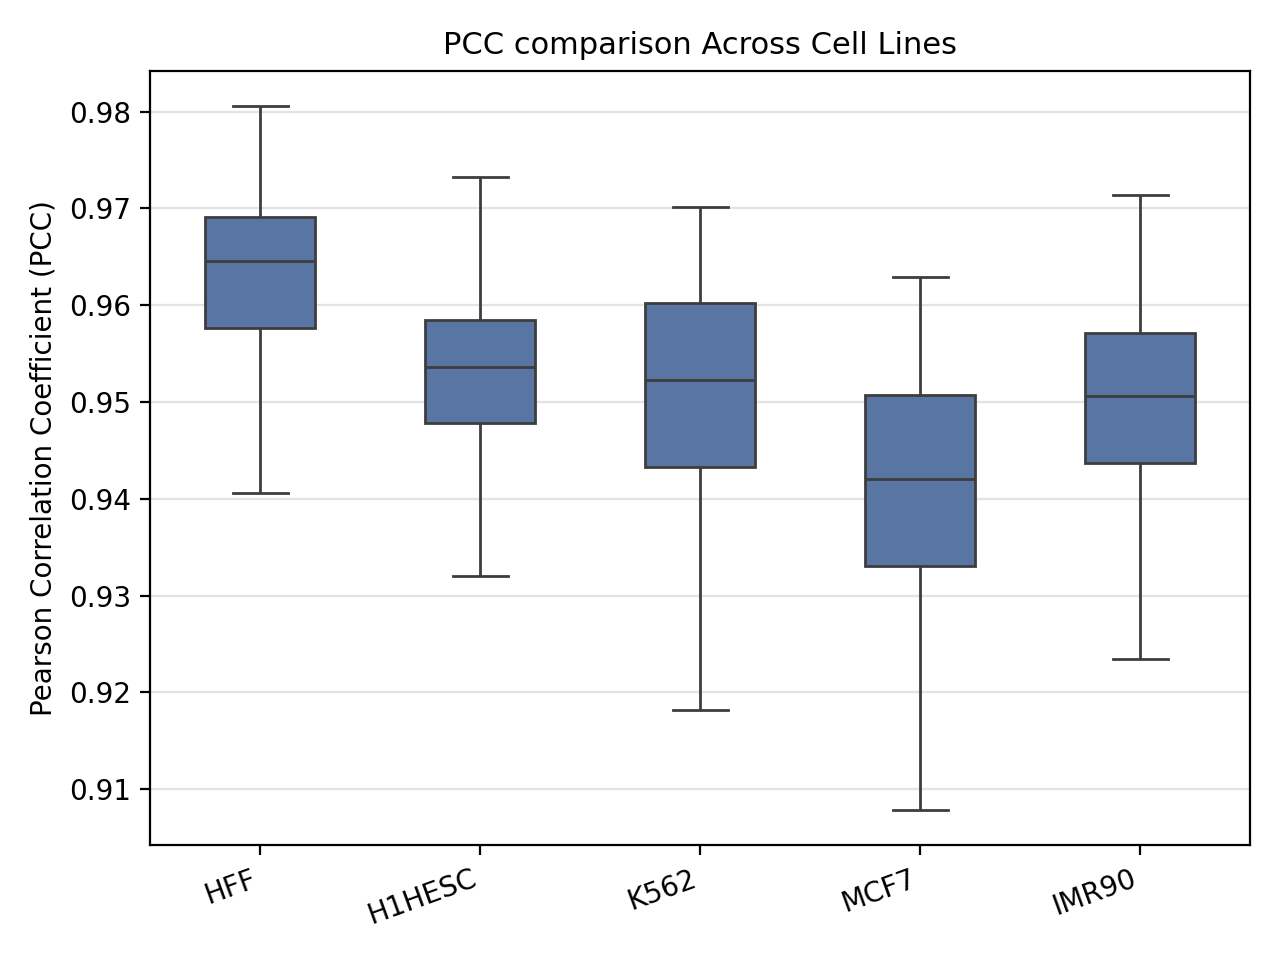

**fig3b_spearman_chr7.png**

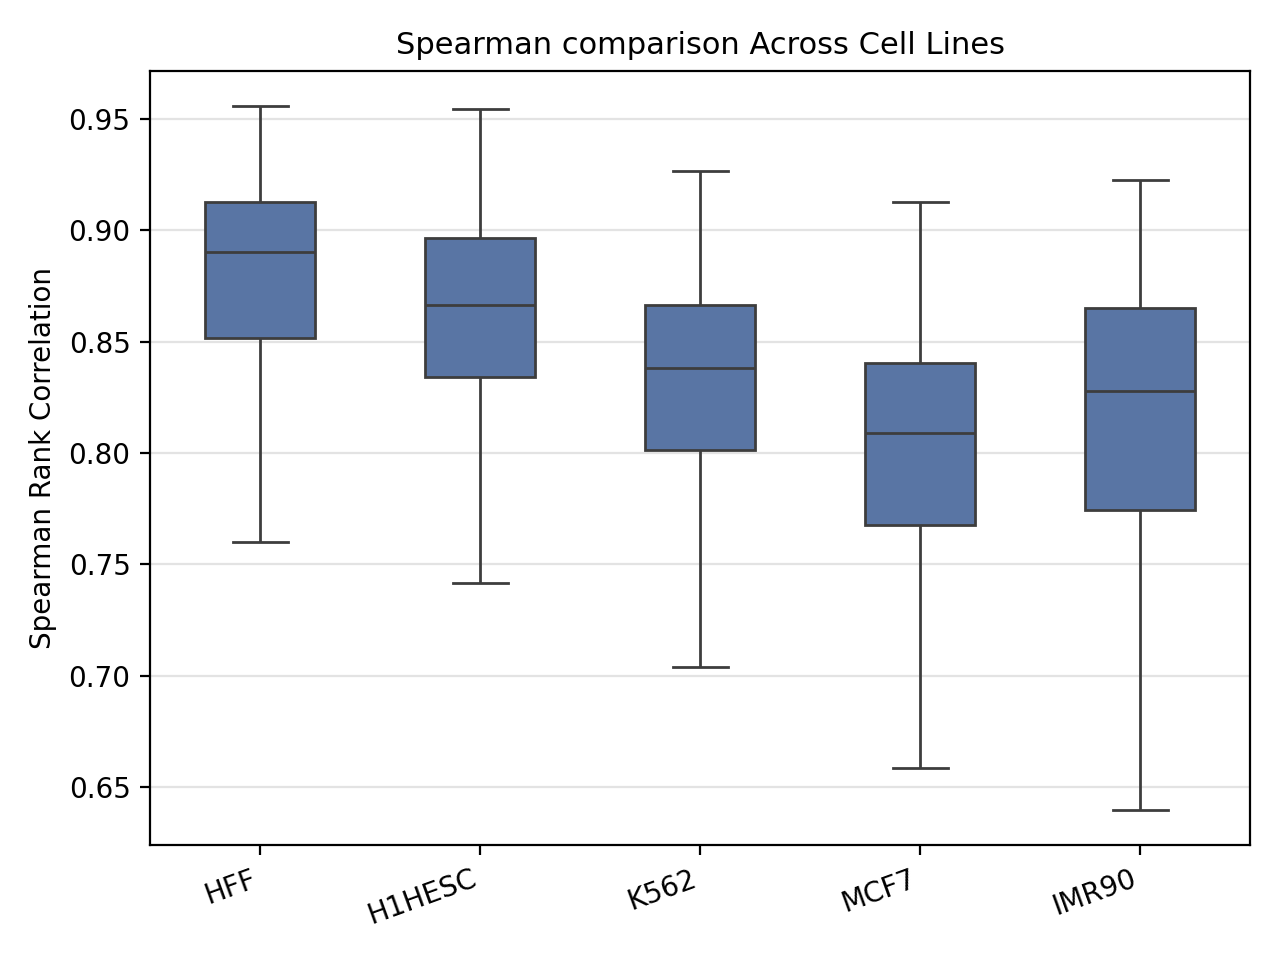

In [10]:
labels = [label for _, label in CELLS]
specs = [("pcc_sm", "PCC comparison Across Cell Lines",
          "Pearson Correlation Coefficient (PCC)", f"fig3a_pcc_{chrom}.png"),
         ("spearman_sm", "Spearman comparison Across Cell Lines",
          "Spearman Rank Correlation", f"fig3b_spearman_{chrom}.png")]
for key, title, ylabel, fname in specs:
    fig, ax = plt.subplots(figsize=(6.4, 4.8))
    sns.boxplot(data=[data[l][key] for l in labels], ax=ax, width=0.5, color="#4C72B0",
                showfliers=False)
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=20, ha="right")
    ax.set_ylabel(ylabel); ax.set_title(title, fontsize=11)
    ax.grid(axis="y", alpha=0.35)
    fig.tight_layout()
    with BytesIO() as buffer:
        fig.savefig(buffer, format="png", dpi=200)
        display(Markdown("**" + fname + "**"))
        display(Image(data=buffer.getvalue(), width=900))
    plt.close(fig)
